# Обнаружение фишинговых ссылок
Учебный проект по машинному обучению. Сравниваем логистическую регрессию и kNN. Цель — определить, является ли ссылка фишинговой.

## 1. Библиотеки и данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

sns.set_style("whitegrid")

In [2]:
from pathlib import Path

data_path = Path("dataset_phishing.csv")
if not data_path.exists():
    data_path = Path("data/dataset_phishing.csv")

df = pd.read_csv(data_path)
print("Размер данных:", df.shape)
df.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [3]:
print(df["status"].value_counts())
df["target"] = (df["status"] == "phishing").astype(int)
df = df.drop(columns="status")

status
legitimate    5715
phishing      5715
Name: count, dtype: int64


## 2. Знакомство с данными

In [4]:
df.info()
print("Пропусков:", df.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  str    
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  11430 non-null

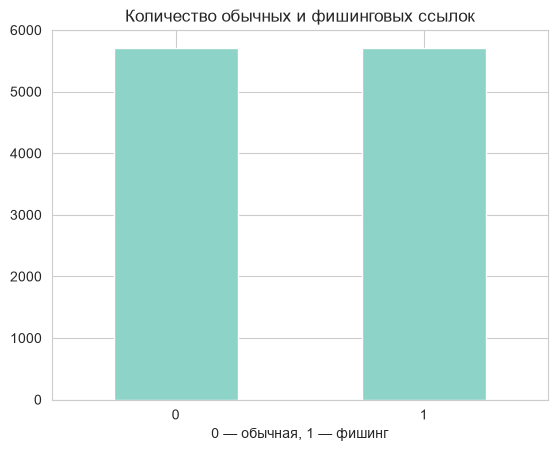

In [5]:
df["target"].value_counts().sort_index().plot(kind="bar")
plt.title("Количество обычных и фишинговых ссылок")
plt.xlabel("0 — обычная, 1 — фишинг")
plt.xticks(rotation=0)
plt.show()

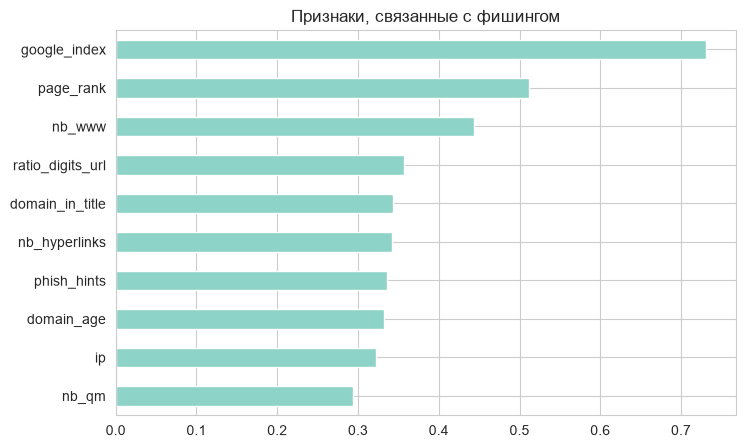

In [6]:
numeric = df.select_dtypes(include="number").drop(columns="target")

useful_columns = []
for column in numeric.columns:
    if numeric[column].nunique() > 1:
        useful_columns.append(column)

correlations = numeric[useful_columns].corrwith(df["target"]).abs().sort_values(ascending=False)
print(correlations.head(10))
correlations.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Признаки, связанные с фишингом")
plt.show()

## 3. Очистка и новые признаки

In [7]:
print("Повторяющихся URL:", df["url"].duplicated().sum())
df = df.drop_duplicates(subset="url").reset_index(drop=True)

constant_columns = []
for column in df.columns:
    if df[column].nunique(dropna=False) <= 1:
        constant_columns.append(column)
df = df.drop(columns=constant_columns)
print("Удалено постоянных столбцов:", len(constant_columns))

Повторяющихся URL: 1
Удалено постоянных столбцов: 6


Пропусков в таблице нет, но у `domain_age` и `domain_registration_length` есть отрицательные значения. Возраст не может быть меньше нуля, так авторы датасета записали «нет данных». Заменяем их на пропуски, а заполним их позже медианой обучающей выборки.

In [8]:
# Возраст домена не может быть отрицательным: -1 и -2 означают «нет данных»
for column in ["domain_age", "domain_registration_length"]:
    print(column, "— отрицательных значений:", (df[column] < 0).sum())
    df.loc[df[column] < 0, column] = np.nan

print("Пропусков после замены:", df.isna().sum().sum())

domain_age — отрицательных значений: 1837
domain_registration_length — отрицательных значений: 46
Пропусков после замены: 1883


In [9]:
def count_host_digits(url):
    host = urlparse(str(url)).hostname
    if host is None:
        host = ""
    count = 0
    for letter in host:
        if letter.isdigit():
            count = count + 1
    return count

def count_suspicious_words(url):
    words = ["login", "signin", "verify", "account", "update", "secure", "bank", "password"]
    url = str(url).lower()
    count = 0
    for word in words:
        count = count + url.count(word)
    return count

Новые признаки:
- `digits_in_host` — цифры в домене. Фишинговые сайты часто подделывают названия: `g00gle`, `paypa1`.
- `susp_words` — слова login, verify, bank и похожие. Ими фишинговые ссылки изображают «официальный» сайт.
- `is_https` — начинается ли ссылка с https. Проверяем, правда ли у фишинга реже бывает HTTPS.

In [10]:
df["digits_in_host"] = df["url"].apply(count_host_digits)
df["susp_words"] = df["url"].apply(count_suspicious_words)
df["is_https"] = df["url"].str.lower().str.startswith("https://").astype(int)
print(df[["digits_in_host", "susp_words", "is_https"]].describe())

       digits_in_host    susp_words      is_https
count    11429.000000  11429.000000  11429.000000
mean         0.630676      0.221017      0.389098
std          2.560061      0.664339      0.487567
min          0.000000      0.000000      0.000000
25%          0.000000      0.000000      0.000000
50%          0.000000      0.000000      0.000000
75%          0.000000      0.000000      1.000000
max         48.000000      6.000000      1.000000


## 4. Разделение выборки
60% — обучение, 20% — подбор параметров, 20% — окончательная проверка. Тестовую часть не используем при выборе модели.

In [11]:
X = df.drop(columns=["url", "target"])
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)
print("Train:", len(X_train), "Validation:", len(X_val), "Test:", len(X_test))

Train: 6857 Validation: 2286 Test: 2286


In [12]:
# Заполняем пропуски медианами из обучающей выборки
medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

print("Пропуски после обработки:", X_train.isna().sum().sum())

Пропуски после обработки: 0


In [13]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

## 5. Логистическая регрессия

In [14]:
logreg = LogisticRegression(max_iter=2000, random_state=42)
logreg.fit(X_train_s, y_train)
logreg_pred = logreg.predict(X_val_s)
print("F1 на validation:", round(f1_score(y_val, logreg_pred), 4))

F1 на validation: 0.9438


## 6. Метод k ближайших соседей (kNN)

In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
knn_pred = knn.predict(X_val_s)
print("F1 на validation:", round(f1_score(y_val, knn_pred), 4))

F1 на validation: 0.935


## 7. Подбор параметров

In [16]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
train_scores = []
val_scores = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_s, y_train)
    train_scores.append(f1_score(y_train, model.predict(X_train_s)))
    val_scores.append(f1_score(y_val, model.predict(X_val_s)))

best_k = k_values[val_scores.index(max(val_scores))]
print("Лучшее k:", best_k)

Лучшее k: 5


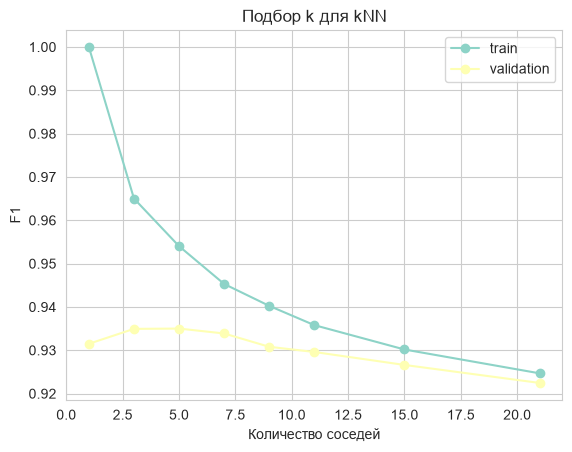

In [17]:
plt.plot(k_values, train_scores, marker="o", label="train")
plt.plot(k_values, val_scores, marker="o", label="validation")
plt.xlabel("Количество соседей")
plt.ylabel("F1")
plt.title("Подбор k для kNN")
plt.legend()
plt.show()

При k = 1 качество на train равно 1, а на validation заметно ниже — модель запомнила обучающие данные (переобучение). С ростом k линии сближаются. Выбираем k с лучшим F1 на validation.

In [18]:
c_values = [0.01, 0.1, 1, 10, 100]
train_scores_c = []
val_scores_c = []
for c in c_values:
    model = LogisticRegression(C=c, max_iter=2000, random_state=42)
    model.fit(X_train_s, y_train)
    train_scores_c.append(f1_score(y_train, model.predict(X_train_s)))
    val_scores_c.append(f1_score(y_val, model.predict(X_val_s)))

best_c = c_values[val_scores_c.index(max(val_scores_c))]
print("Лучшее C:", best_c)

Лучшее C: 0.1


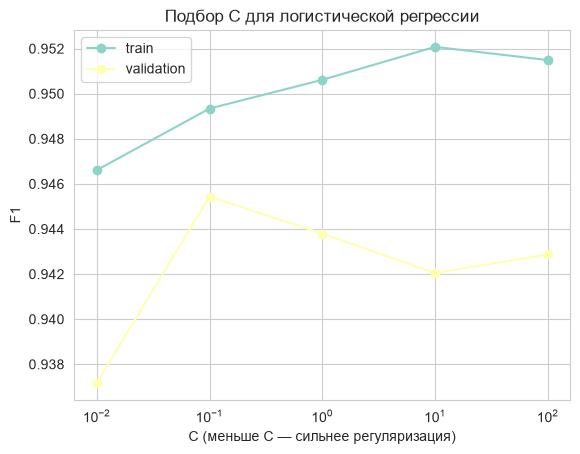

In [19]:
plt.plot(c_values, train_scores_c, marker="o", label="train")
plt.plot(c_values, val_scores_c, marker="o", label="validation")
plt.xscale("log")
plt.xlabel("C (меньше C — сильнее регуляризация)")
plt.ylabel("F1")
plt.title("Подбор C для логистической регрессии")
plt.legend()
plt.show()

## 8. Сравнение моделей

In [20]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_s, y_train)

logreg_best = LogisticRegression(C=best_c, max_iter=2000, random_state=42)
logreg_best.fit(X_train_s, y_train)

models = {"Logistic Regression": logreg_best, "kNN": knn_best}

In [21]:
rows = []
for name, model in models.items():
    pred = model.predict(X_val_s)
    proba = model.predict_proba(X_val_s)[:, 1]
    rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "ROC-AUC": roc_auc_score(y_val, proba)
    })
comparison = pd.DataFrame(rows).set_index("Модель")
comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Logistic Regression,0.9453,0.9434,0.9475,0.9454,0.9843
kNN,0.9366,0.9586,0.9125,0.9350,0.9727


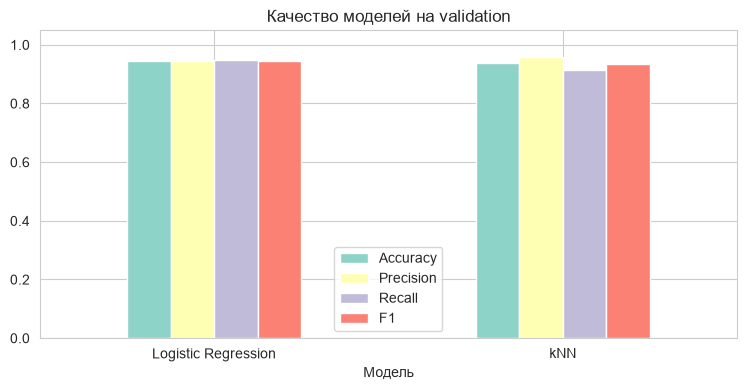

In [22]:
comparison[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4))
plt.ylim(0, 1.05)
plt.title("Качество моделей на validation")
plt.xticks(rotation=0)
plt.show()

In [23]:
best_name = comparison["F1"].idxmax()
final_model = models[best_name]
print("Выбрана модель:", best_name)

Выбрана модель: Logistic Regression


## 9. Проверка на тестовой выборке
Тестовые данные используются один раз после выбора модели.

In [24]:
test_pred = final_model.predict(X_test_s)
test_proba = final_model.predict_proba(X_test_s)[:, 1]
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred), 4))
print("Recall:", round(recall_score(y_test, test_pred), 4))
print("F1:", round(f1_score(y_test, test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))

Accuracy: 0.9453
Precision: 0.9473
Recall: 0.9431
F1: 0.9452
ROC-AUC: 0.9853


In [25]:
# Сравниваем F1 на трёх выборках
parts = [("train", X_train_s, y_train), ("validation", X_val_s, y_val), ("test", X_test_s, y_test)]
for part_name, X_part, y_part in parts:
    pred = final_model.predict(X_part)
    print(part_name, "F1:", round(f1_score(y_part, pred), 4))

train F1: 0.9493
validation F1: 0.9454
test F1: 0.9452


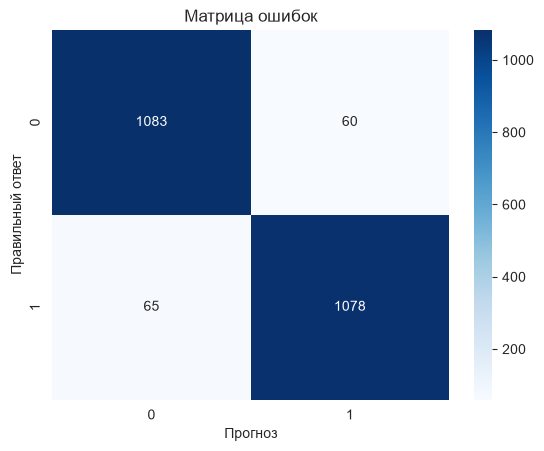

In [26]:
print(classification_report(y_test, test_pred, target_names=["Обычная", "Фишинг"]))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Матрица ошибок")
plt.xlabel("Прогноз")
plt.ylabel("Правильный ответ")
plt.show()

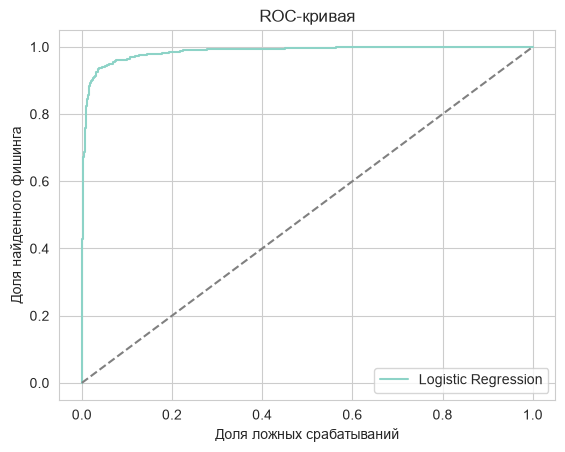

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, test_proba)
plt.plot(fpr, tpr, label=best_name)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Доля ложных срабатываний")
plt.ylabel("Доля найденного фишинга")
plt.title("ROC-кривая")
plt.legend()
plt.show()

## 10. Какие признаки важны для логистической регрессии

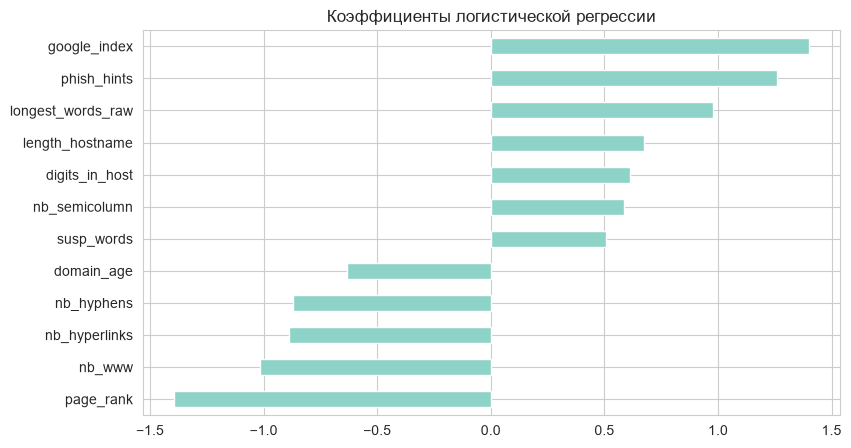

In [28]:
coefficients = pd.Series(logreg_best.coef_[0], index=X_train.columns)
important = coefficients.abs().sort_values(ascending=False).head(12).index
coefficients[important].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Коэффициенты логистической регрессии")
plt.show()

## 11. Итог

- В исходном датасете 11 430 ссылок: 5 715 обычных и 5 715 фишинговых. Удалили 1 повторяющуюся ссылку и 6 постоянных столбцов.
- Заменили 1 883 отрицательных значения возраста и срока регистрации домена на пропуски. Пропуски заполнили медианами, рассчитанными только по обучающей выборке.
- Добавили три признака: количество цифр в домене, количество подозрительных слов и использование HTTPS.
- Для подбора параметров использовали validation, а для итоговой оценки — отдельную тестовую выборку.
- Лучшей по F1 на validation оказалась логистическая регрессия с C = 0.1. У kNN лучшее k = 5.
- На тесте логистическая регрессия получила Accuracy = 94.53%, Precision = 94.73%, Recall = 94.31%, F1 = 94.52%, ROC-AUC = 98.53%.
- На тесте модель пропустила 65 фишинговых ссылок из 1 143 и ошибочно отметила 60 обычных ссылок как фишинговые.
- F1 на train = 0.9493, validation = 0.9454, test = 0.9452. Явных признаков сильного переобучения не видно.